In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from tqdm import tqdm


# Tensorflow: check available devices
all_devices = tf.config.list_physical_devices()
print('Found {} devices: {}'.format( len(all_devices), all_devices ))

Found 1 devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


---

# Fetch the Dataset

* ESC-50: a dataset for Environmental Sound Classification (https://github.com/karolpiczak/ESC-50, https://www.karolpiczak.com/papers/Piczak2015-ESC-Dataset.pdf)
 * 50 classes, 40 files per class, 5s clips

In [ ]:
# !wget https://github.com/karolpiczak/ESC-50/archive/master.zip
# !unzip master.zip

In [2]:
fn_csv = 'ESC-50-master/meta/esc50.csv'

df = pd.read_csv(fn_csv)  # reads csv, creates dataframe
print(df.head())
unique_classes = df['category'].unique()  # retrieves a list of unique classes
print(f'\nUnique classes: {unique_classes}\nCount: {len(unique_classes)}')

            filename  fold  target        category  esc10  src_file take
0   1-100032-A-0.wav     1       0             dog   True    100032    A
1  1-100038-A-14.wav     1      14  chirping_birds  False    100038    A
2  1-100210-A-36.wav     1      36  vacuum_cleaner  False    100210    A
3  1-100210-B-36.wav     1      36  vacuum_cleaner  False    100210    B
4  1-101296-A-19.wav     1      19    thunderstorm  False    101296    A

Unique classes: ['dog' 'chirping_birds' 'vacuum_cleaner' 'thunderstorm' 'door_wood_knock'
 'can_opening' 'crow' 'clapping' 'fireworks' 'chainsaw' 'airplane'
 'mouse_click' 'pouring_water' 'train' 'sheep' 'water_drops'
 'church_bells' 'clock_alarm' 'keyboard_typing' 'wind' 'footsteps' 'frog'
 'cow' 'brushing_teeth' 'car_horn' 'crackling_fire' 'helicopter'
 'drinking_sipping' 'rain' 'insects' 'laughing' 'hen' 'engine' 'breathing'
 'crying_baby' 'hand_saw' 'coughing' 'glass_breaking' 'snoring'
 'toilet_flush' 'pig' 'washing_machine' 'clock_tick' 'sneezing' '

---

# ESC-5: Curation

Let's select 5 classes (*our_classes*) from ESC-50 to make things a bit faster.

In [3]:
fn_csv = "ESC-50-master/meta/esc50.csv"

our_classes = ["crying_baby", "dog", "rain", "rooster", "sneezing"]  # Note: This is also our class map for later.
esc5_X = []  # File list
esc5_y = []  # Class list

df = pd.read_csv(fn_csv)  # reads csv, creates dataframe
df.values

for row in df.values:  # (This particular algorithm here works, but is not ideal)
  if any(row[3] == k for k in our_classes):
    esc5_X.append(row[0])  # Filename column
    esc5_y.append(row[3])  # Class column

print( list(zip(esc5_X[:5], esc5_y[:5])) )
print(f"Lengths: esc5_X: {len(esc5_X)}, esc5_y: {len(esc5_y)}")


[('1-100032-A-0.wav', 'dog'), ('1-110389-A-0.wav', 'dog'), ('1-17367-A-10.wav', 'rain'), ('1-187207-A-20.wav', 'crying_baby'), ('1-211527-A-20.wav', 'crying_baby')]
Lengths: esc5_X: 200, esc5_y: 200


---

# Splitting the dataset into *train* and *test* subsets

***Tasks:***
* ESC-5 is almost ready. With **sklearn**, split the dataset into **train** and **test** subsets with a 80%/20% split ratio and random state 1337.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(esc5_X, esc5_y, test_size=0.2, random_state=1337)  # Look at your imports for a hint which function to use.
print(f"X: {len(X_train)}, {len(X_test)}; y: {len(y_train)}, {len(y_test)}")

X: 160, 40; y: 160, 40


---
# ESC-5: Create mel spectrograms

In [6]:
### START CODING HERE ###
def extract_mel_spec(X_train, y_train):
  X = []  # feature tensor
  y = []  # target tensor

  mel_bands = 128
  for i, filename in tqdm(enumerate(X_train)):  # tqdm displays a progress bar.
    wav_data, sr = librosa.load(f"ESC-50-master/audio/{filename}",sr=None)  # Use the wav file's sample rate.

    # Features
    mel_spec = librosa.feature.melspectrogram(y=wav_data, sr=sr, n_mels=mel_bands)  # Create mel spectrogram. Output shape: (128, 216) (n_mels, frames)
    mel_spec = mel_spec/mel_bands  # Normalization
    mel_spec = mel_spec.T  # Transposition. Output shape: (216, 128)
    X.append( mel_spec )  # Append to feature tensor

    # Targets == class_name
    targets = np.ones( mel_spec.shape[0] )  # Create a PLACEHOLDER target vector. Output shape: (216) (Note: silent frames are NOT going to be labeled as "silent")
    targets = targets * our_classes.index( y_train[i] )  # Convert values to actual class-index from 'our_classes'
    y.append(targets)  # Append to target tensor

  # Stack tensors
  X = np.vstack(X)
  y = np.hstack(y)

  # Return the tensors
  return X, y


# Call the function on our previously generated lists
X_train_ready, y_train_ready = extract_mel_spec(X_train, y_train)
X_test_ready, y_test_ready = extract_mel_spec(X_test, y_test)
### END CODING HERE ###


print(f"\nShapes: X_train_ready: {X_train_ready.shape}, y_train_ready: {y_train_ready.shape}")
print(f"Shapes: X_test_ready: {X_test_ready.shape}, y_test_ready: {y_test_ready.shape}")

160it [00:02, 53.88it/s] 
40it [00:00, 95.80it/s] 



Shapes: X_train_ready: (68960, 128), y_train_ready: (68960,)
Shapes: X_test_ready: (17240, 128), y_test_ready: (17240,)


---

# Train a nearest neighbor classifier

***Tasks:***
* Use the features and targets from above to **train/fit** a kNN-classifier from sklearn, with 5 neighbors and uniform weighting.
* Print the scores on the train set and test set. Round to 4 decimals with **np.round**. (This will take some time!)


In [7]:
# Feature scaling/standardization: removes mean & scales to unit variance
print("Scaling...")
scaler = StandardScaler()
scaler.fit(X_train_ready)
X_train_ready = scaler.transform(X_train_ready)  # Normalize the features here for both train and test
X_test_ready = scaler.transform(X_test_ready)

print("Fitting...")
model = KNeighborsClassifier(n_neighbors=5, weights='uniform')  # Call the kNN-classifier. Look at your imports again for a hint.
model.fit(X_train_ready, y_train_ready)  # Fit/Train the classifier using our generated tensors.

print("Evaluating...")
print(f"Train score: {np.round(model.score(X_train_ready, y_train_ready), decimals=4)}")
print(f"Test score: {np.round(model.score(X_test_ready, y_test_ready), decimals=4)}")

Scaling...
Fitting...
Evaluating...
Train score: 0.7817
Test score: 0.5692


---

# ESC-5: Plot the confusion matrix
We want to learn more about our classifier. How well does it perform per class?

***Tasks:***
* Using sklearn, create a confusion matrix of our classifier over the **test set**
* Normalize the rows, use **our_classes** as axes tick values
* Display the plot

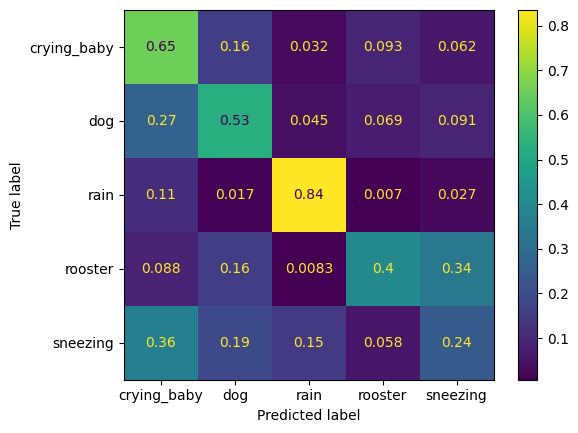

In [8]:
y_test_pred = model.predict(X_test_ready)  # Predict the test set
cm = confusion_matrix(y_test_pred, y_test_ready, normalize='true')  # Call the confusion matrix function. Look at your imports again for a hint.
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=our_classes)  # Create a display object for the confusion matrix. Look at your imports again for a hint.
disp.plot()
plt.xticks(ticks=np.arange(5), labels=our_classes)  # hint: np.arange(5) = (0, 1, 2, 3, 4)
plt.yticks(ticks=np.arange(5), labels=our_classes)
plt.show()

---

# **Getting to know Tensorflow for Neural Networks**
# Import Tensorflow modules

In [30]:
from keras.models import Sequential, Model
from keras.layers import Input, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from keras.optimizers import SGD
from keras.losses import CategoricalCrossentropy, SparseCategoricalCrossentropy
from keras.utils import to_categorical
from keras import regularizers
from keras.callbacks import EarlyStopping, ModelCheckpoint

---

# 1. One-Hot Encoding (OHE) of targets (binary class matrix)

Situation in our dataset:
* We have 5 classes, and only 1 class is always active --> This is a **multi-class** problem.
* Thus, we **categorize** our targets. A OHE'd target with index "3" becomes [0 0 0 1 0] (mapped against the output).
* https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical

In [21]:
print(f"y_train_ready.shape: {y_train_ready.shape}, y_test_ready.shape: {y_test_ready.shape}")  # These are our shapes so far.

y_train_ready_OHE = to_categorical(y_train_ready, num_classes=len(our_classes))  # One-hot encode the target tensors.
y_test_ready_OHE = to_categorical(y_test_ready, num_classes=len(our_classes))  # One-hot encode the target tensors.

print(f"y_train_ready_OHE.shape: {y_train_ready_OHE.shape}, y_test_ready_OHE.shape: {y_test_ready_OHE.shape}")  # These are our new shapes.

y_train_ready.shape: (68960,), y_test_ready.shape: (17240,)
y_train_ready_OHE.shape: (68960, 5), y_test_ready_OHE.shape: (17240, 5)


---
# 2. Build a simple DNN (Sequential API & Functional API)

* Building an NN can be straightforward. Let's build a simple, extendable
architecture.
* Training and evaluating an NN is very similar to what you saw for the kNN-classifier.
* Sequential API: https://machinelearningmastery.com/tutorial-first-neural-network-python-keras/
* Functional API: https://machinelearningmastery.com/keras-functional-api-deep-learning/

In [38]:
model_seq = Sequential()
model_seq.add(Input(shape=(128,)))  # input layer. Note: This is the shape of the input tensor, not the mel spectrogram.
model_seq.add(Dense(128, activation="relu"))   # hidden layer 1
model_seq.add(Dense(256, activation="relu"))   # hidden layer 1
model_seq.add(Dense(64, activation="relu"))    # hidden layer 2
model_seq.add(Dense(5, activation="softmax"))  # output layer. Often this is sigmoid (each index can be between 0 and 1), or softmax (all indices sum up to 1)

WITH DROPOUT AND KERNEL REGULARIZATION

In [ ]:
# Sequential API
reguralization= 0.01

model_seq = Sequential()
model_seq.add(Input(shape=(128,)))  # input layer. Note: This is the shape of the input tensor, not the mel spectrogram.
model_seq.add(Dense(128, activation="relu", kernel_regularizer=regularizers.l2(reguralization)))   # hidden layer 1
model_seq.add(Dropout(0.2))  # dropout layer
model_seq.add(Dense(256, activation="relu", kernel_regularizer=regularizers.l2(reguralization)))   # hidden layer 1
model_seq.add(Dropout(0.2))  # dropout layer
model_seq.add(Dense(64, activation="relu", kernel_regularizer=regularizers.l2(reguralization)))    # hidden layer 2
model_seq.add(Dropout(0.2))  # dropout layer
model_seq.add(Dense(5, activation="softmax"))  # output layer. Often this is sigmoid (each index can be between 0 and 1), or softmax (all indices sum up to 1)

EARLY STOPPING

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Create the early stopping callback
early_stop = EarlyStopping(
    monitor='val_loss',       # What to monitor (could be 'val_accuracy' etc.)
    patience=5,               # How many epochs to wait after no improvement
    restore_best_weights=True # Optional: keeps the best model, not the last one
)

# Train the model with the callback
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],  # Add the callback here
    verbose=1
)

In [ ]:
# Functional API (node-like)
model_func_in = Input(shape=(128,))                               # input layer
model_func_x = Dense(128, activation="relu")(model_func_in)        # hidden layer 1
model_func_x = Dense(256, activation="relu")(model_func_x)         # hidden layer 2
model_func_x = Dense(64, activation="relu")(model_func_x)         # hidden layer 3
model_func_out = Dense(5, activation="softmax")(model_func_x)     # output layer
model_func = Model(inputs=model_func_in, outputs=model_func_out)  # model instance, specified with input and output layers

In [45]:
# To simplify the following cells, select a desired model here
model = model_seq
# model = model_func

# model.compile(optimizer=SGD(learning_rate=0.001), loss=CategoricalCrossentropy(), metrics=["accuracy"])  # Compiles the model
model.compile(optimizer=SGD(learning_rate=0.001), loss=SparseCategoricalCrossentropy(), metrics=["accuracy"])  # Compiles the model

# -> Given this loss function, "accuracy" means "Categorical Accuracy". Notice how "Categorical" relates to OHE

model.summary()  # Prints the architecture

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,309 (259.02 KB)

 Trainable params: 66,309 (259.02 KB)

 Non-trainable params: 0 (0.00 B)

Now, **train** the model on the **train set** with the **OHE targets** for 10 epochs.


In [46]:
#history = model.fit(x=X_train_ready, y=y_train_ready, epochs=10)
# history = model.fit(x=X_train_ready, y=y_train_ready_OHE, epochs=10, validation_data=(X_test_ready, y_test_ready_OHE))  # Validation data
history = model.fit(x=X_train_ready, y=y_train_ready, epochs=30, validation_split=0.2, batch_size=32)  # Validation split
# history = model.fit(x=X_train_ready, y=y_train_ready_OHE, epochs=10, batch_size=32)  # Batch size
# history = model.fit(x=X_train_ready, y=y_train_ready_OHE, epochs=10, batch_size=32, validation_split=0.2)  # Validation split
# history = model.fit(x=X_train_ready, y=y_train_ready_OHE, epochs=10, batch_size=32, validation_split=0.2, shuffle=True)  # Shuffle

Epoch 1/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 2s 872us/step - accuracy: 0.2520 - loss: 5.5663 - val_accuracy: 0.2871 - val_loss: 5.3152
Epoch 2/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 1s 780us/step - accuracy: 0.4171 - loss: 5.1648 - val_accuracy: 0.2512 - val_loss: 5.0120
Epoch 3/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 1s 777us/step - accuracy: 0.4462 - loss: 4.8456 - val_accuracy: 0.2662 - val_loss: 4.7443
Epoch 4/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 1s 807us/step - accuracy: 0.4628 - loss: 4.5383 - val_accuracy: 0.2820 - val_loss: 4.4831
Epoch 5/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 1s 777us/step - accuracy: 0.4738 - loss: 4.2729 - val_accuracy: 0.2936 - val_loss: 4.2508
Epoch 6/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 2s 887us/step - accuracy: 0.4768 - loss: 4.0347 - val_accuracy: 0.2996 - val_loss: 4.0460
Epoch 7/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 1s 833us/step - accuracy: 0.4760 - loss: 3.8311 - val_accuracy: 0.3039 - val_loss: 3.8554
Epoch 8/30
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 1s 826us/step - accuracy: 0.4822 -

Let's print the training loss and the accuracy

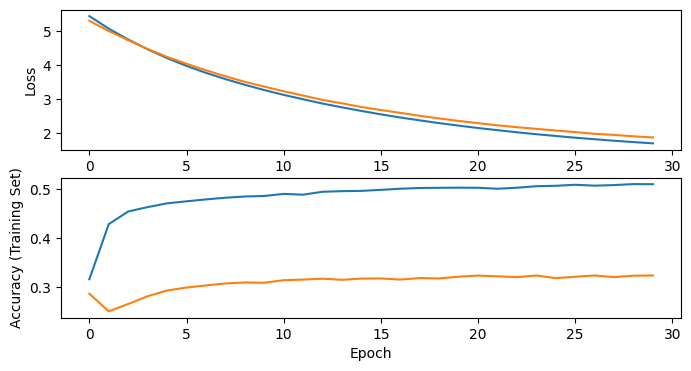

In [47]:
plt.figure(figsize=(8, 4))
plt.subplot(2,1,1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('Loss')
plt.subplot(2,1,2)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.ylabel('Accuracy (Training Set)')
plt.xlabel('Epoch')
plt.show()

Now, **evaluate** the model on the **test set** and print the scores.

In [48]:
### START CODING HERE ###
score = model.evaluate(x=X_test_ready, y=y_test_ready, return_dict=True, verbose=1)
print(f"Scores:{score}")
### END CODING HERE ###

539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step - accuracy: 0.3774 - loss: 1.9261
Scores:{'accuracy': 0.46745941042900085, 'loss': 1.808079719543457}


Finally, we would like to see the confusion matrix for this model.
* Use the **predict**-function to classify the **test set**. This will give us "predicted targets".
* Because the targets & predictions are vectors (remember OHE), we need their **argmax** along a certain axis.
 * argmax retrieves the index at which the array contains the highest value.

539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 349us/step
Shape of predictions: (17240, 128)


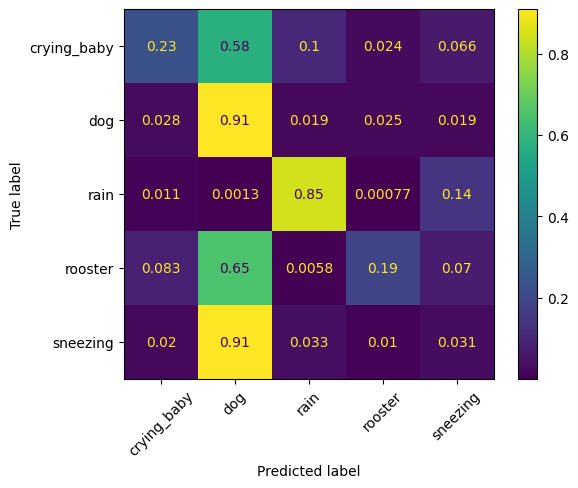

In [49]:
# Predict the test set
predictions = model.predict(X_test_ready)
print(f"Shape of predictions: {X_test_ready.shape}")

# Plot confusion matrix
confmat = confusion_matrix(y_true=y_test_ready, y_pred=np.argmax(predictions,axis=1), normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=confmat, display_labels=our_classes)
disp.plot(xticks_rotation=45)  # rotate labels on x-axis for readability
plt.show()

---
# 3. Build a simple CNN (Functional API)

**CNN: Preparation of tensors**
* For 2D convolutional layers, we need to reshape our tensors.
* 2D conv layers take a 4D-input of the form NHWC: *(num_examples, height, width, channels)*.
  * **num_examples**: (in this case) total number of frames (for the train set)
  * **height**: number of time frames per example, here: 1
  * **width**: feature dimension, here: 128
  * **channels**: audio channels, here: 1 (mono)

**IMPORTANT NOTES:**
* Above numbers are valid for our frame-based approach.
We could also translate *num_examples* to number of files, then each example would have a *height* of 216 (because each file has 216 frames).
* In our particular example, we could also use 1D conv layers with, e.g., kernel_size=(3). Same for MaxPooling.

In [57]:
# Input layer
model_cnn_in = Input(shape=(1, 128, 1))  # Why 3 dims here...? "num_examples" can be left "unknown". Note "(None)" in the summary. (See next cell for more info.)

# Hidden layers
model_cnn_conv1 = Conv2D(filters=32, kernel_size=(1, 3), activation="relu")(model_cnn_in)  # Input is a vector (1, 128), so (1, 3) spans the kernel only over the feature dimension
model_cnn_pool1 = MaxPooling2D(pool_size=(1, 2))(model_cnn_conv1)                          # Same as above: We pool only in frequency dimension
model_cnn_conv2 = Conv2D(filters=64, kernel_size=(1, 3), activation="relu")(model_cnn_pool1)
model_cnn_pool2 = MaxPooling2D(pool_size=(1, 2))(model_cnn_conv2)
model_cnn_conv2 = Conv2D(filters=128, kernel_size=(1, 3), activation="relu")(model_cnn_pool2)

# Towards backend
model_cnn_flat = Flatten()(model_cnn_conv2)
model_cnn_drop1 = Dropout(0.2)(model_cnn_flat)
model_cnn_dense1 = Dense(64, activation="relu")(model_cnn_drop1)

# Output layer
model_cnn_out = Dense(5, activation="softmax")(model_cnn_dense1)

# Actual model creation
model_cnn = Model(inputs=model_cnn_in, outputs=model_cnn_out)
model_cnn.compile(optimizer=SGD(learning_rate=0.1), loss=CategoricalCrossentropy(), metrics=["accuracy"])
model_cnn.summary()

Model: "functional_31"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 1, 128, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 1, 126, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 63, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 61, 64)      │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 30, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 1, 28, 128)     │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3584)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 3584)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │       229,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 260,805 (1018.77 KB)

 Trainable params: 260,805 (1018.77 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
# Convert tensors to correct input shape (for both training and test sets)
print(f"Shapes: X_train_ready {X_train_ready.shape}, y_train_ready_OHE {y_train_ready_OHE.shape}")
# Shape X_train_ready: (34560, 128)    <-- needs format adjustment
# Shape y_train_ready_OHE: (34560, 5)  <-- already in correct format

# potentially: feed more "height" (time) in by switching dimensions to (1, 34560, 128, 1), then slicing the tensor into 160 tensors (with 216 frames each, essentially per-file training then)

# Add channel dimension
X_train_cnn = np.expand_dims(X_train_ready, axis=-1)  # (34560, 128, 1)
X_test_cnn = np.expand_dims(X_test_ready, axis=-1)   # (8640, 128, 1)

# Add height dimension
X_train_cnn = np.expand_dims(X_train_cnn, axis=1)  # (34560, 1, 128, 1)
X_test_cnn = np.expand_dims(X_test_cnn, axis=1)   # (8640, 1, 128, 1)

# New shapes
print(f"Final shapes: X_train_cnn {X_train_cnn.shape}, X_test_cnn {X_test_cnn.shape}")

Shapes: X_train_ready (68960, 128), y_train_ready_OHE (68960, 5)
Final shapes: X_train_cnn (68960, 1, 128, 1), X_test_cnn (17240, 1, 128, 1)


**Train** the CNN on the correct tensors for 10 epochs with a batch size of 16.

In [58]:
history = model_cnn.fit(x=X_train_cnn, y=y_train_ready_OHE, batch_size=16, epochs=10)

Epoch 1/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.5028 - loss: 1.0996
Epoch 2/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.6228 - loss: 0.8313
Epoch 3/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.6407 - loss: 0.7949
Epoch 4/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6504 - loss: 0.7725
Epoch 5/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.6651 - loss: 0.7467
Epoch 6/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.6693 - loss: 0.7312
Epoch 7/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.6748 - loss: 0.7205
Epoch 8/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6774 - loss: 0.7178
Epoch 9/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6804 - loss: 0.7103
Epoch 10/10
4310/4310 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.6851 - loss: 0.6952


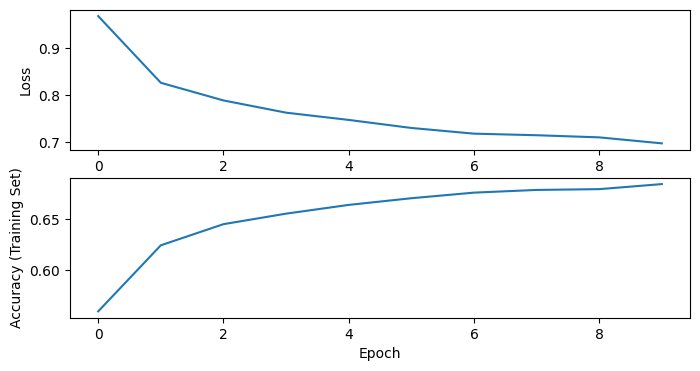

In [59]:
plt.figure(figsize=(8, 4))
plt.subplot(2,1,1)
plt.plot(history.history['loss'])
# plt.plot(history.history['val_loss'])
plt.ylabel('Loss')
plt.subplot(2,1,2)
plt.plot(history.history['accuracy'])
# plt.plot(history.history['val_accuracy'])
plt.ylabel('Accuracy (Training Set)')
plt.xlabel('Epoch')
plt.show()

**Evaluate** the CNN on the **test set** and print the scores.


In [60]:
scores = model_cnn.evaluate(X_test_cnn,y_test_ready_OHE, return_dict=True, verbose=1)
print(f"Scores:{scores}")

539/539 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6367 - loss: 1.0742
Scores:{'accuracy': 0.6322506070137024, 'loss': 1.0880955457687378}


Semi-expected output:
```
270/270 [==============================] - 1s 5ms/step - loss: 1.0290 - accuracy: 0.5950
Scores: {'loss': 1.0289990901947021, 'accuracy': 0.5950231552124023}
```

**Confusion matrix**: Get the predictions for the **test set**, then consider the **argmax** again.

539/539 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Shape of predictions: (17240, 1, 128, 1)


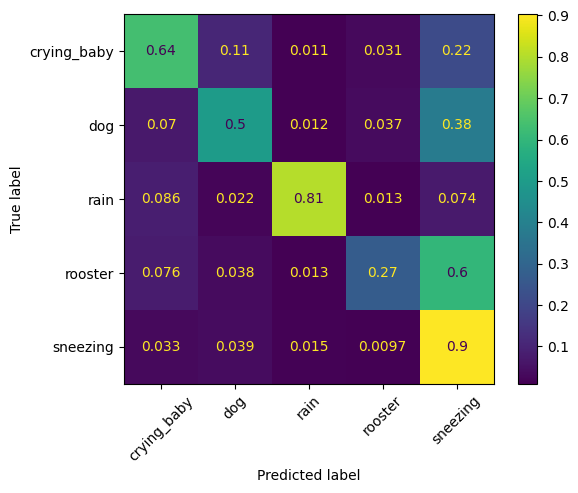

In [61]:
# Predict test set
predictions = model_cnn.predict(X_test_cnn)
print(f"Shape of predictions: {X_test_cnn.shape}")

# Plot confusion matrix
confmat = confusion_matrix(y_true=y_test_ready, y_pred=np.argmax(predictions,axis=1), normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=confmat, display_labels=our_classes)
disp.plot(xticks_rotation=45)
plt.show()

# Repeat at signal level

In [131]:
### START CODING HERE ###
def extract_mel_spec(X_train, y_train):
  X = []  # feature tensor
  y = []  # target tensor

  mel_bands = 128
  for i, filename in tqdm(enumerate(X_train)):  # tqdm displays a progress bar.
    wav_data, sr = librosa.load(f"ESC-50-master/audio/{filename}",sr=None)  # Use the wav file's sample rate.

    # Features
    mel_spec = librosa.feature.melspectrogram(y=wav_data, sr=sr, n_mels=mel_bands)  # Create mel spectrogram. Output shape: (128, 216) (n_mels, frames)
    mel_spec = mel_spec/mel_bands  # Normalization
    mel_spec = mel_spec.T  # Transposition. Output shape: (216, 128)
    X.append( mel_spec )  # Append to feature tensor

    # Targets == class_name
    targets = our_classes.index( y_train[i] )  # Convert values to actual class-index from 'our_classes'
    y.append(targets)  # Append to target tensor

  # Return the tensors
  return X, y


# Call the function on our previously generated lists
X_train_ready, y_train_ready = extract_mel_spec(X_train, y_train)
X_test_ready, y_test_ready = extract_mel_spec(X_test, y_test)

160it [00:02, 79.46it/s]
40it [00:00, 89.50it/s]


In [133]:
# Normalize the features here for both train and test
scaler = StandardScaler()

X_train_scaled = []
X_test_scaled = []

for spec in X_train_ready:
  X_train_scaled.append(scaler.fit_transform(spec))

for spec in X_test_ready:
  X_test_scaled.append(scaler.fit_transform(spec))

X_train_scaled = np.asarray(X_train_scaled)
X_test_scaled = np.asarray(X_test_scaled)

y_train_ready = np.asarray(y_train_ready)
y_test_ready = np.asarray(y_test_ready)

print(f"\nShapes: X_train_ready: {X_train_scaled.shape}, y_train_ready: {y_train_ready.shape}")
print(f"Shapes: X_test_ready: {X_train_scaled.shape}, y_test_ready: {y_test_ready.shape}")


Shapes: X_train_ready: (160, 431, 128), y_train_ready: (160,)
Shapes: X_test_ready: (160, 431, 128), y_test_ready: (40,)


In [134]:
X_train_cnn = np.expand_dims(X_train_scaled, axis=-1) 
X_test_cnn = np.expand_dims(X_test_scaled, axis=-1)   
print(f"Shapes: X_train_scaled: {X_train_cnn.shape}, y_train_ready: {X_train_cnn.shape}")
print(f"Shapes: X_test_scaled: {X_test_cnn.shape}, y_test_ready: {X_test_cnn.shape}")

Shapes: X_train_scaled: (160, 431, 128, 1), y_train_ready: (160, 431, 128, 1)
Shapes: X_test_scaled: (40, 431, 128, 1), y_test_ready: (40, 431, 128, 1)


In [145]:
# Input shape per sample: (431 time steps, 128 features, 1 channel)
input_shape = (X_train_cnn.shape[1], X_train_cnn.shape[2], 1)
model_cnn2_in = Input(shape=input_shape)

# Convolutional layers
x = Conv2D(filters=32, kernel_size=(3, 3), activation="relu", kernel_regularizer=regularizers.l2(0.1))(model_cnn2_in)
x = MaxPooling2D(pool_size=(3, 3))(x)
x = Dropout(0.1)(x)

x = Conv2D(filters=32, kernel_size=(3, 3), activation="relu",kernel_regularizer=regularizers.l2(0.1))(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Dropout(0.1)(x)

x = Conv2D(filters=64, kernel_size=(2, 2), activation="relu",kernel_regularizer=regularizers.l2(0.1))(x)

# Flatten and dense layers
x = Flatten()(x)
x = Dense(32, activation="relu",kernel_regularizer=regularizers.l2(0.1))(x)
x = Dropout(0.1)(x)

# Output layer (5 classes)
model_cnn2_out = Dense(5, activation="softmax")(x)

# Define and compile model
model_cnn2 = Model(inputs=model_cnn2_in, outputs=model_cnn2_out)
model_cnn2.compile(optimizer=SGD(learning_rate=0.1),
                   loss=SparseCategoricalCrossentropy(),
                   metrics=["accuracy"])

model_cnn2.summary()

Model: "functional_52"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_36 (InputLayer)     │ (None, 431, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_72 (Conv2D)              │ (None, 429, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_50 (MaxPooling2D) │ (None, 143, 42, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_64 (Dropout)            │ (None, 143, 42, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_73 (Conv2D)              │ (None, 141, 40, 32)    │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_51 (MaxPooling2D) │ (None, 70, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_65 (Dropout)            │ (None, 70, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_74 (Conv2D)              │ (None, 69, 19, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_22 (Flatten)            │ (None, 83904)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 32)             │     2,684,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_66 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_69 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,702,949 (10.31 MB)

 Trainable params: 2,702,949 (10.31 MB)

 Non-trainable params: 0 (0.00 B)

In [146]:
history = model_cnn2.fit(x=X_train_cnn, y=y_train_ready, validation_split=0.2, epochs=30)


Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step - accuracy: 0.3365 - loss: 15.2794 - val_accuracy: 0.3438 - val_loss: 13.5389
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 222ms/step - accuracy: 0.3750 - loss: 13.0448 - val_accuracy: 0.3125 - val_loss: 11.7905
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 220ms/step - accuracy: 0.5802 - loss: 11.2428 - val_accuracy: 0.3125 - val_loss: 10.3597
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 221ms/step - accuracy: 0.5896 - loss: 9.6143 - val_accuracy: 0.3438 - val_loss: 9.0083
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 221ms/step - accuracy: 0.6135 - loss: 8.4462 - val_accuracy: 0.4375 - val_loss: 8.0124
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 222ms/step - accuracy: 0.6750 - loss: 7.1596 - val_accuracy: 0.5000 - val_loss: 7.0451
Epoch 7/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 221ms/step - accuracy: 0.6552 - loss: 6.2592 - val_accuracy: 0.2812 - val_loss: 6.3329
Epoch 8/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 219ms/step - accuracy: 0.5594 - loss: 5.8189 - val_accuracy: 0.4375 - val

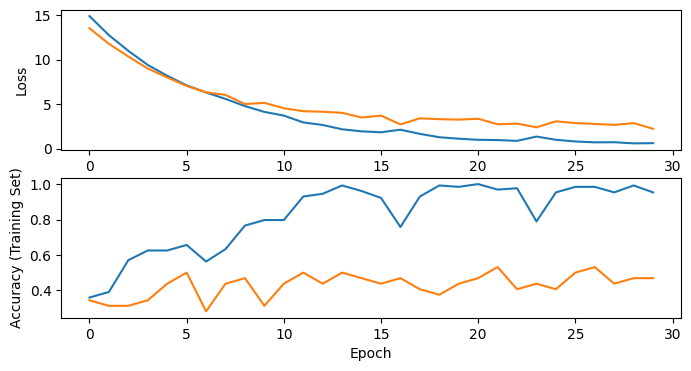

In [147]:
plt.figure(figsize=(8, 4))
plt.subplot(2,1,1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('Loss')
plt.subplot(2,1,2)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.ylabel('Accuracy (Training Set)')
plt.xlabel('Epoch')
plt.show()

In [143]:
scores = model_cnn2.evaluate(X_test_cnn,y_test_ready, return_dict=True, verbose=1)
print(f"Scores:{scores}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4458 - loss: 2.8135 
Scores:{'accuracy': 0.44999998807907104, 'loss': 2.7798285484313965}


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step 
Shape of predictions: (40, 431, 128, 1)


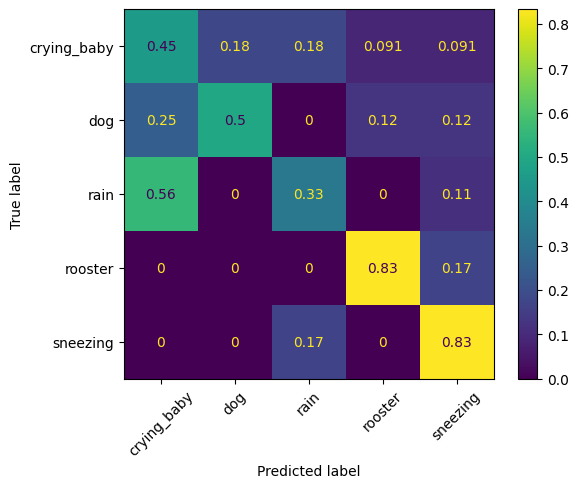

In [148]:
# Predict test set
predictions = model_cnn2.predict(X_test_cnn)
print(f"Shape of predictions: {X_test_cnn.shape}")

# Plot confusion matrix
confmat = confusion_matrix(y_true=y_test_ready, y_pred=np.argmax(predictions,axis=1), normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=confmat, display_labels=our_classes)
disp.plot(xticks_rotation=45)
plt.show()

---

# 13. Hyper-parameter tuning

Try playing around with these values and see how it affects the results:

* **learning rate**: go in steps of an order of (half) magnitude, e.g. 1.0, 0.1, 0.01, 0.005...
* **batch size**: e.g. 1, 16, 32, 216. 216 will result in 160 batches. Where have you seen this number before?